# 07. Agentic RAG

## Problem

Two real citations can still support a false relationship: restore approval does not establish incident command. First retrieve the right active sources, then verify each claim.

## Learning objectives

Compute BM25 and cosine similarity; fuse rankings with RRF; rerank candidates; bound query reformulation; preserve active revisions; identify missing and contradictory evidence.

Run top to bottom in a fresh kernel. The default path uses temporary storage and scripted inference with actual framework orchestration. Every plotted value is labelled measured, estimated or illustrative.

In [1]:
import os
from pathlib import Path
from tempfile import TemporaryDirectory
from IPython.display import display
ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "pyproject.toml").exists())
scratch = TemporaryDirectory(prefix="northstar-course-")
os.environ["MPLCONFIGDIR"] = str(Path(scratch.name) / "matplotlib")
os.environ["LANGSMITH_TRACING"] = "false"
os.environ["LANGCHAIN_TRACING_V2"] = "false"
import matplotlib
get_ipython().run_line_magic("matplotlib", "inline")
import matplotlib.pyplot as plt
from deep_agent_lab.settings import Settings
from deep_agent_lab.courseware import diagram, bars
settings = Settings(_env_file=None, deep_lab_mode="demo", langfuse_enabled=False,
                    deep_lab_state_dir=Path(scratch.name) / "state")
assert settings.deep_lab_mode == "demo" and not settings.langfuse_enabled

## Concept explanation

## Existing Northstar retrieval architecture

Your repository already implements a meaningful hybrid retrieval pipeline.

The actual repository also validates embedding profiles and handles revision cleanup.

This is worth understanding before adding an "agentic" layer.

## BM25: lexical relevance

BM25 is a ranking function designed around term matching, term frequency, document frequency, and document length.

A common BM25 formulation is:

$$ \operatorname{BM25}(q,d) = \sum_{t\in q} \operatorname{IDF}(t) \frac{f(t,d)(k_1+1)} {f(t,d)+k_1(1-b+b|d|/\overline{|d|})} $$

Here:

- $ f(t,d) $ is the frequency of term $ t $ in document $ d $.
- $ |d| $ is document length.
- $ \overline{|d|} $ is average document length.
- $ \operatorname{IDF}(t) $ reflects term rarity.
- $ k_1 $ controls term-frequency saturation.
- $ b $ controls document-length normalization.

The exact IDF variant and search behavior depend on the engine.

### **Why term rarity matters**

Suppose the user searches:

> SEV-1 incident commander

The term "incident" may appear throughout the corpus.

"SEV-1" and "commander" may be more discriminative.

BM25 accounts for that distinction.

It is particularly useful for exact policy names, identifiers, unusual terminology, and specific error codes.

Production Northstar delegates BM25 to OpenSearch. The notebook reimplements it to expose the ranking arithmetic.

The purpose of learning the formula is understanding why a keyword result ranks highly or poorly.

## Vector retrieval: semantic similarity

An embedding model transforms text into a numerical vector:

$$ f(\text{text}) \rightarrow \mathbf{v}\in\mathbb{R}^d $$

A query and document passage are embedded into a comparable vector space.

A common similarity measure is cosine similarity:

$$ \operatorname{cosine}(a,b) = \frac{a\cdot b} {\\|a\\|\\|b\\|} $$

```
Query:
Who coordinates responders during a major outage?

Document:
The Incident Commander coordinates SEV-1 responders.
```

The wording is different, but vector retrieval may recognize semantic similarity.

### **Limitations**

Vector similarity is not proof of factual relevance.

A passage about restore authorization may be semantically close to a question about incident command without answering it.

Vectors also depend on the embedding model, preprocessing, and indexing configuration. Changing models without rebuilding the index can invalidate the meaning of existing vectors even when dimensions match.

Northstar already accounts for embedding-profile compatibility.

## Reciprocal rank fusion

BM25 and vector scores generally occupy different scales.

Combining raw scores directly can therefore be misleading.

Reciprocal rank fusion (RRF) combines rankings instead:

$$ \operatorname{RRF}(d) = \sum_{r \in R} \frac{1}{k+\operatorname{rank}_r(d)} $$

The repository uses `k=60`.

Suppose:

| Document | BM25 rank | Vector rank |
| -------- | --------- | ----------- |
| A        | 1         | 3           |
| B        | 2         | 1           |
| C        | 3         | 2           |

The combined scores are:

$$ A=\frac{1}{61}+\frac{1}{63} $$

$$ B=\frac{1}{62}+\frac{1}{61} $$

$$ C=\frac{1}{63}+\frac{1}{62} $$

RRF rewards documents that appear prominently across retrieval methods.

The `seen` set prevents one retrieval list from counting duplicate IDs repeatedly.

The result is a ranked list, not a statement that any document supports a particular conclusion.

## Agentic retrieval: retrieve according to uncertainty

Direct RAG generally performs a predetermined retrieval operation.

Agentic retrieval allows subsequent retrieval steps to depend on intermediate findings.

Northstar begins with:

> Compare restore and incident approval responsibilities.

A useful bounded sequence is:

```
1. Search restore authorization.
2. Search incident coordination.
3. Identify the unresolved intersection.
4. Search specifically for joint approval or role transfer.
5. Stop if sufficient evidence is found,
   or report the unresolved question.
```

The agent should not search indefinitely.

### **Query decomposition**

A broad question can be decomposed into narrower evidence requirements.

```
questions = [    "Who approves production restoration?",    "Who coordinates SEV-1 response?",    "Does any current policy assign joint authority?",]
```

This improves observability because every subquestion has an expected evidence category.

### **Bounded query reformulation**

A retrieval policy might allow one targeted reformulation after an empty result, then require abstention or escalation.

The model should not repeatedly issue semantically identical queries merely because no answer was found.

### **Optional reranking**

A reranker examines a smaller candidate set and estimates query-document relevance more directly.

A typical pipeline is:

```
BM25 + vector retrieval
        ↓
RRF top 20
        ↓
Optional reranker
        ↓
Top 5 evidence passages
        ↓
Claim verification
```

Reranking can improve selection but adds latency, model dependencies, and another component to evaluate.

For Northstar's small fictional corpus, hybrid retrieval may already be sufficient.

## Structured claims

Instead of treating the entire answer as one unverifiable string, represent factual findings as separate claims.

A supported example:

```
{
  "text": "The database operations lead approves production restores.",
  "references": [
    {
      "evidence_id": "northstar-restore",
      "revision": "4",
      "quote": "The database operations lead approves production restores."
    }
  ]
}
```

An unsupported example:

```
{
  "text": "The Database Operations Lead automatically becomes Incident Commander.",
  "references": [
    {
      "evidence_id": "northstar-restore",
      "revision": "4",
      "quote": "The database operations lead approves production restores."
    }
  ]
}
```

The second reference resolves to a real bundled passage. Its content does not establish the claim. Support is a separate Verdict, rather than a self-declared property of the Claim record.

These human-readable evidence IDs are teaching fixtures. The existing repository generates bracketed citation tokens derived from evidence IDs, such as `[[<12-character-hash>]]`. In an actual integration, resolve those exact tokens back to the corresponding stored evidence records rather than relying on a human-readable alias.

## Three levels of citation correctness

| Check             | Question                                                   |
| ----------------- | ---------------------------------------------------------- |
| Citation validity | Does the citation resolve to a real evidence record?       |
| Citation coverage | Does every factual claim have an appropriate citation?     |
| Claim support     | Does the referenced evidence actually establish the claim? |

These properties are independent.

An answer could have 100% citation coverage and still contain unsupported claims.

The save tool validates citation membership. `evidence.py` adds revision and exact-quote checks, a conservative complete-sentence verifier, and an optional model-judge adapter. Human review remains responsible for arbitrary semantic claims in a proposed brief.

## Deterministic evidence validation

Start by checking properties that do not require a language model.

This code verifies provenance and excerpt fidelity.

It does **not** verify semantic entailment.

```
Claim:
"Restore approval is not required."

Evidence:
"Restore approval is required."
```

The source and quotation may both be valid, while the claim contradicts the evidence.

Semantic support can be assessed using a carefully constrained model judge, human review, or task-specific logic. No single method is infallible.

## Missing, contradictory, and stale evidence

Northstar must distinguish three cases.

**Missing evidence:** No retrieved policy establishes the required fact. The assistant should explain what remains unknown and what source is needed.

**Contradictory evidence:** Two applicable sources make incompatible statements. The assistant should preserve both, compare scope and effective dates, and avoid choosing arbitrarily.

**Stale evidence:** A source revision has been superseded. A valid citation to an old revision is not necessarily valid evidence of the current rule.

A useful answer could be:

> BKP-7 revision 4 assigns restore approval to the Database Operations Lead. INC-3 revision 8 assigns incident coordination to the Incident Commander. Neither excerpt establishes automatic transfer of authority between those roles. A joint approval procedure remains an evidence gap.

This is more useful than inventing a convenient relationship.

## Mental model

Read the following diagram as an application boundary: the model proposes actions while the runtime performs validated operations. The figure renders through Matplotlib in the notebook output.

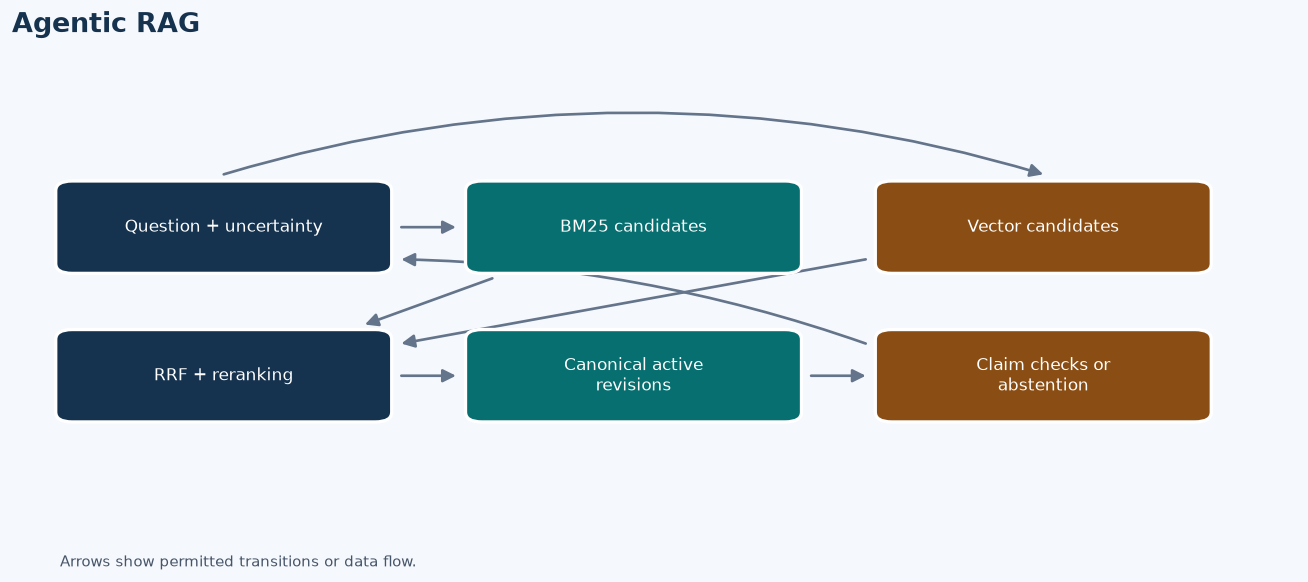

In [2]:
display(diagram('Agentic RAG', ['Question + uncertainty', 'BM25 candidates', 'Vector candidates', 'RRF + reranking', 'Canonical active revisions', 'Claim checks or abstention'], [(0, 1), (0, 2), (1, 3), (2, 3), (3, 4), (4, 5), (5, 0)]))
plt.close('all')

## Implementation from scratch

Build the smallest inspectable mechanism before connecting it to the full application. The code below exposes state and checks the invariant that motivates this module.

In [3]:
import math
from collections import Counter
from deep_agent_lab.knowledge import fixture_search
from deep_agent_lab.retrieval import terms, bm25, vector_rank, hybrid, rerank, adaptive_search
rows = fixture_search("restore incident access recovery", 5)
documents = [Counter(terms(row.excerpt)) for row in rows]
average_length = sum(sum(doc.values()) for doc in documents) / len(documents)

def bm25_one(query, doc, k1=1.2, b=0.75):
    score = 0.0
    for term in set(terms(query)):
        df = sum(term in other for other in documents)
        idf = math.log(1 + (len(documents) - df + 0.5) / (df + 0.5))
        f = doc[term]
        score += idf * f * (k1+1) / (f + k1*(1-b+b*sum(doc.values())/average_length))
    return score

manual = {row.id: bm25_one("production restore", doc) for row,doc in zip(rows,documents)}
ranked = bm25("production restore", rows)
assert ranked[0]["_id"] == "northstar-restore"
assert abs(ranked[0]["_score"] - manual["northstar-restore"]) < 1e-10
# Illustrative 2-D vectors expose cosine arithmetic; these are NOT learned semantic embeddings.
vectors = {"northstar-restore": [1.,0.], "northstar-incident": [0.,1.]}
semantic = vector_rank([0.8,0.2], vectors)
fused = hybrid(ranked, semantic)
print("BM25:", ranked)
print("Illustrative vector ranking:", semantic)
print("RRF:", fused)

BM25: [{'_id': 'northstar-restore', '_score': 2.873391589349953}]
Illustrative vector ranking: [{'_id': 'northstar-restore', '_score': 0.9701425001453318}, {'_id': 'northstar-incident', '_score': 0.24253562503633294}]
RRF: [{'_id': 'northstar-restore', '_score': 0.03278688524590164}, {'_id': 'northstar-incident', '_score': 0.016129032258064516}]


## Framework implementation

The following cell executes the existing Deep Agents/LangGraph application or its actual integration boundary. Any fixture ports or scripted responses are identified in the cell.

In [4]:
from deep_agent_lab.rag.pipeline import RagService
from deep_agent_lab.rag.models import SearchRequest
from types import SimpleNamespace

# Exercise the existing pipeline with explicit fixture ports, not fake external services.
# The pipeline still performs its actual fusion and canonical hydration logic.
canonical = {row.id: {"chunk_id": row.id, "document_id": row.source, "title": row.title,
                     "source": row.source, "position": row.position, "text": row.excerpt,
                     "revision": row.revision} for row in rows}
candidate_rows = [{"_id": "stale-orphan", "_score": 100.0}, *ranked]
pipeline = RagService.__new__(RagService)
pipeline.settings = SimpleNamespace(retrieval_candidates=30)
pipeline.index = SimpleNamespace(validate_profile=lambda: None,
    keyword=lambda query,count: candidate_rows, semantic=lambda vector,count: semantic)
pipeline.ollama = SimpleNamespace(embed=lambda texts,purpose: [[0.8,0.2]])
pipeline.db = SimpleNamespace(hydrate=lambda ids: {key:canonical[key] for key in ids if key in canonical})
hits = pipeline._search(SearchRequest(query="production restore", mode="hybrid", top_k=3))
assert hits and all(hit.chunk_id != "stale-orphan" for hit in hits)
assert hits[0].revision == "4"
print([(hit.chunk_id,hit.revision) for hit in hits])

[('northstar-restore', '4'), ('northstar-incident', '8')]


## Code walkthrough

BM25 weights rare terms and saturates term frequency while normalizing document length. Cosine compares direction in one embedding space. RRF uses rank positions because BM25 and vector scores have different scales. The offline vector coordinates are illustrative arithmetic fixtures. Real learned embeddings come from Ollama in the optional live exercise. The existing pipeline hydrates candidate IDs from canonical SQL, excluding orphaned or inactive index records. A reranker scores query/passage relevance; it does not establish claim entailment.

## Interactive experiments

Vary the RRF constant and compare keyword, vector and fused evidence recall. Use an explicitly lexical teaching reranker, then try a bounded empty-query reformulation.

keyword {'recall': 1.0, 'precision': 0.5, 'mrr': 1.0, 'relevant_count': 1, 'retrieved_count': 1}
illustrative vector {'recall': 1.0, 'precision': 0.5, 'mrr': 1.0, 'relevant_count': 1, 'retrieved_count': 2}
hybrid {'recall': 1.0, 'precision': 0.5, 'mrr': 1.0, 'relevant_count': 1, 'retrieved_count': 2}
Executed query sequence: ['zephyr-99', 'production restore']


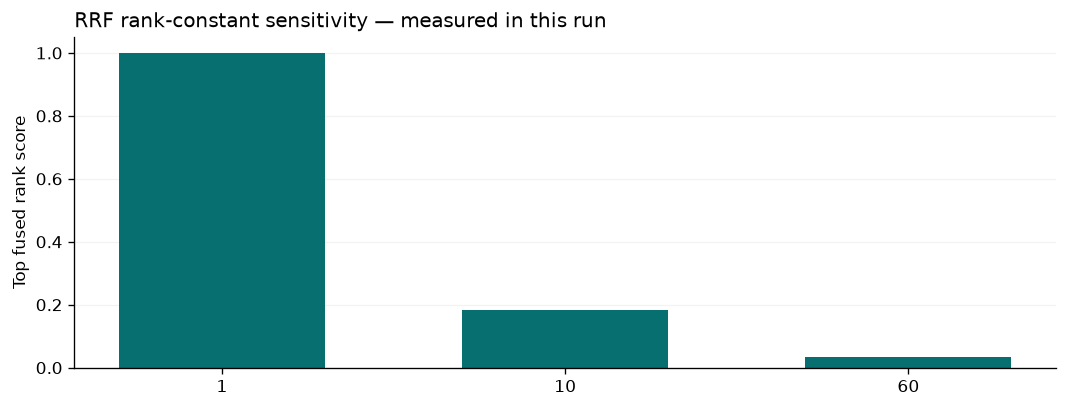

In [5]:
from deep_agent_lab.evaluation import retrieval_metrics
expected = {"northstar-restore"}
for label, ranking in [("keyword",ranked), ("illustrative vector",semantic), ("hybrid",fused)]:
    print(label, retrieval_metrics(expected, [hit["_id"] for hit in ranking], 2))
reranked = rerank("commander", rows, lambda q,text: float(q in text.lower()), top_k=1)
assert reranked[0].id == "northstar-incident"
found, queries = adaptive_search("ZEPHYR-99", lambda q: fixture_search(q,3), lambda q:"production restore")
assert found and len(queries) == 2
print("Executed query sequence:", queries)
display(bars("RRF rank-constant sensitivity",
             {str(k): hybrid(ranked,semantic,k=k)[0]["_score"] for k in [1,10,60]},
             ylabel="Top fused rank score"))
plt.close("all")

## Failure experiment

Deliberately violate a contract or remove a required condition. A caught, asserted failure is an expected result; an uncaught error means this notebook has not passed.

In [6]:
from deep_agent_lab.evidence import Claim, Reference, extractive_verdict
registry = {row.id:row for row in rows}
restore = registry["northstar-restore"]
unsupported = Claim(text="The restore approver automatically becomes Incident Commander.",
    references=[Reference(evidence_id=restore.id, revision=restore.revision, quote=restore.excerpt)])
assert extractive_verdict(unsupported,registry).label == "insufficient"
stale = unsupported.model_copy(update={"references":[Reference(evidence_id=restore.id, revision="5", quote=restore.excerpt)]})
assert "revision_mismatch" in extractive_verdict(stale,registry).reason
print("Valid citation did not establish the claimed relationship.")

Valid citation did not establish the claimed relationship.


## Verification

These assertions inspect actual state produced above. They establish the stated contracts within this lab's scope.

In [7]:
assert hits[0].chunk_id == "northstar-restore"
assert len({hit.chunk_id for hit in hits}) == len(hits)
missing, attempts = adaptive_search("unknown",lambda q:[],lambda q:q)
assert missing == [] and len(attempts) == 1

## Exercise

Write RRF from scratch for two ID lists, deduplicate within each list, and compare it with the repository implementation. Explain why the fused score is not a probability.

Try your implementation before running the complete reference solution in the next cell.

### Reference solution

Compare the implementation and assertions with your attempt.

In [8]:
def rrf(rankings,k=60):
    scores = {}
    for ranking in rankings:
        seen = set()
        for rank,key in enumerate(ranking,1):
            if key not in seen:
                scores[key] = scores.get(key,0) + 1/(k+rank)
                seen.add(key)
    return sorted(scores.items(),key=lambda pair:(-pair[1],pair[0]))
ids = [[hit["_id"] for hit in ranked],[hit["_id"] for hit in semantic]]
assert rrf(ids) == [(hit["_id"],hit["_score"]) for hit in fused]

## Trade-offs and further reading

More candidates or reranking can improve recall at additional latency. An empty successful search permits a bounded reformulation; a failed backend must be reported as unavailable. Source changes require rechecking active revisions. The companion evidence notebook examines provenance, conflict and semantic limits in depth.

[Primary source 1](https://docs.opensearch.org/latest/search-plugins/keyword-search/) · [Primary source 2](https://docs.langchain.com/oss/python/deepagents/retrieval)

## Optional live integration

Install Ollama and initialize/ingest the configured PostgreSQL/OpenSearch corpus as described in `docs/operations.md`. Set RUN_LIVE only when those dependencies are available. This cell is skipped in offline verification. A successful live run still requires claim-level review; token and cost measurements are only meaningful when the provider reports them.

In [9]:
RUN_LIVE = False
if RUN_LIVE:
    from deep_agent_lab.service import AgentService, RunRequest, open_checkpointer
    live = Settings(_env_file=ROOT / ".env", deep_lab_mode="live")
    with open_checkpointer(live) as cp:
        service = AgentService(live, cp)
        try:
            result = service.run(RunRequest(
                prompt="Who approves a production restore? Cite the policy."))
            print(result.model_dump_json(indent=2))
            assert result.evidence and not result.unknown_citations
        finally:
            service.close()

In [10]:
plt.close('all')
scratch.cleanup()
print('All offline module assertions passed.')

All offline module assertions passed.
